In [1]:
# Import pandas for working with DataFrames
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Import OneHotEncoder for categorical data encoding
from sklearn.preprocessing import OneHotEncoder

# Display all columns when viewing a DataFrame
pd.set_option('display.max_columns', None)

# Display graphs inside the notebook
%matplotlib inline

In [2]:
# Import the files module from Google Colab
from google.colab import files

# Upload a file from your computer
uploaded = files.upload()

Saving flight_price.xlsx to flight_price.xlsx


In [3]:
# Load the uploaded Excel file into a DataFrame
df = pd.read_excel('flight_price.xlsx')

# Display the first five rows
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
# Display the last five rows
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [5]:
# Display the number of rows and columns
df.shape

(10683, 11)

In [6]:
# Display all column names
df.columns.tolist()

['Airline',
 'Date_of_Journey',
 'Source',
 'Destination',
 'Route',
 'Dep_Time',
 'Arrival_Time',
 'Duration',
 'Total_Stops',
 'Additional_Info',
 'Price']

In [7]:
# Display information about columns, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [8]:
# Display statistical information about numerical columns
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [9]:
# Count missing values in every column
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [10]:
# Calculate the percentage of missing values in every column
(df.isnull().sum() / len(df)) * 100

,0
Airline,0.000000
Date_of_Journey,0.000000
Source,0.000000
Destination,0.000000
Route,0.009361
Dep_Time,0.000000
Arrival_Time,0.000000
Duration,0.000000
Total_Stops,0.009361
Additional_Info,0.000000


In [11]:
# Count the number of duplicate rows
df.duplicated().sum()

np.int64(220)

In [12]:
# Remove duplicate rows from the dataset
df.drop_duplicates(inplace=True)

# Check the updated dataset dimensions
df.shape

(10463, 11)

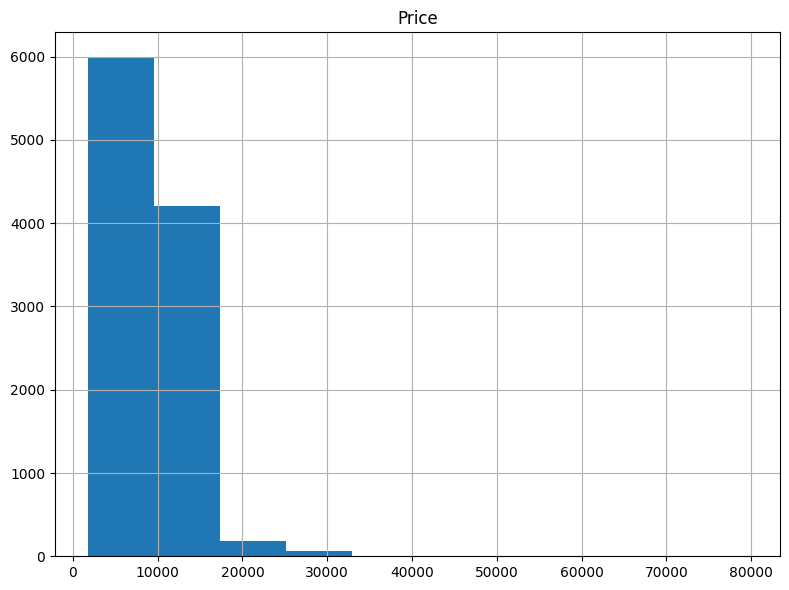

In [15]:
# Select all numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

# Display histograms for numerical columns
df[numerical_cols].hist(figsize=(8, 6))

# Adjust the layout of the graphs
plt.tight_layout()

# Display the graphs
plt.show()

In [16]:
# Select all categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# Display the unique values and their counts
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: Airline
Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1695
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

Column: Date_of_Journey
Date_of_Journey
6/06/2019     490
18/05/2019    486
9/06/2019     485
12/06/2019    483
21/05/2019    482
9/05/2019     466
21/03/2019    412
15/05/2019    402
27/05/2019    369
27/06/2019    339
24/06/2019    330
1/06/2019     330
3/06/2019     326
15/06/2019    314
24/03/2019    314
6/03/2019     302
27/03/2019    290
24/05/2019    286
6/05/2019     282
1/05/2019     274
12/05/2019    259
1/04/2019     256
3/03/201

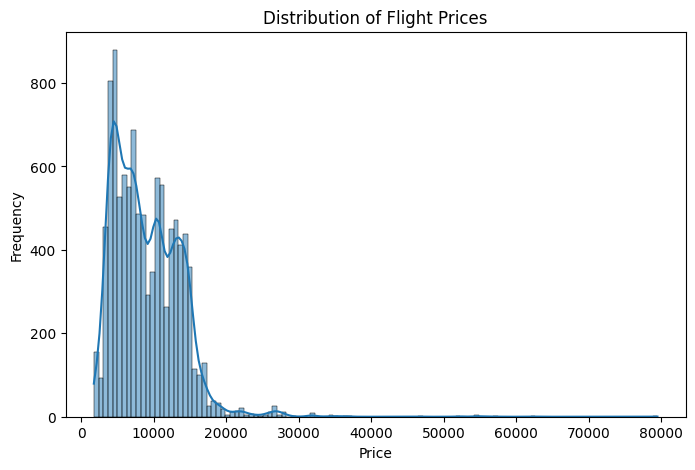

In [17]:
# Display the distribution of flight ticket prices
plt.figure(figsize=(8, 5))

# Create a histogram with a density curve
sns.histplot(df['Price'], kde=True)

# Add graph title
plt.title('Distribution of Flight Prices')

# Add x-axis label
plt.xlabel('Price')

# Add y-axis label
plt.ylabel('Frequency')

# Display the graph
plt.show()

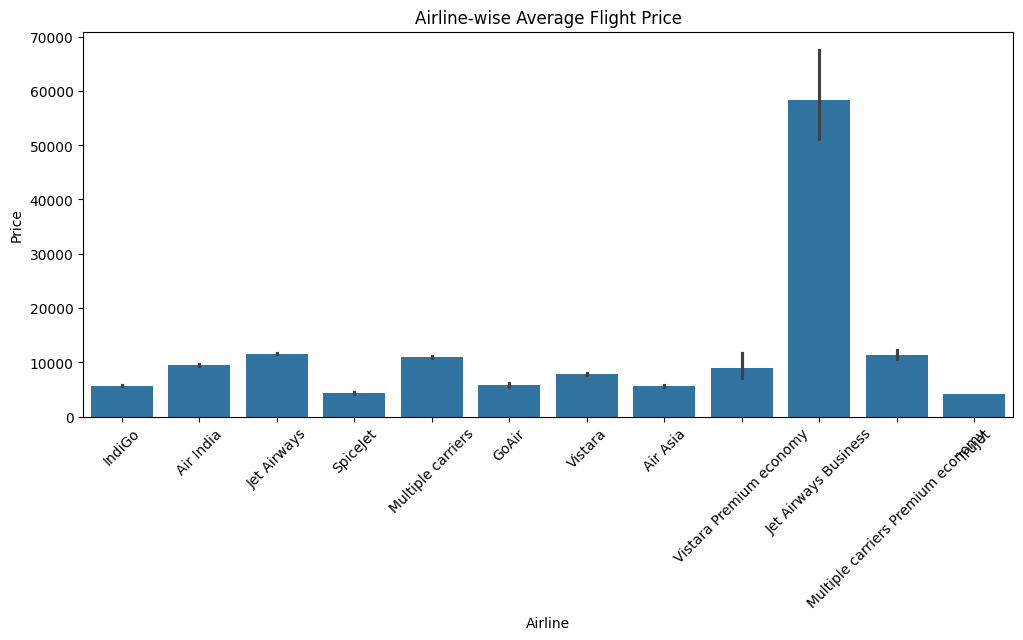

In [18]:
# Create a figure for airline-wise price comparison
plt.figure(figsize=(12, 5))

# Compare average ticket prices for different airlines
sns.barplot(data=df, x='Airline', y='Price')

# Rotate airline names for readability
plt.xticks(rotation=45)

# Add graph title
plt.title('Airline-wise Average Flight Price')

# Display the graph
plt.show()

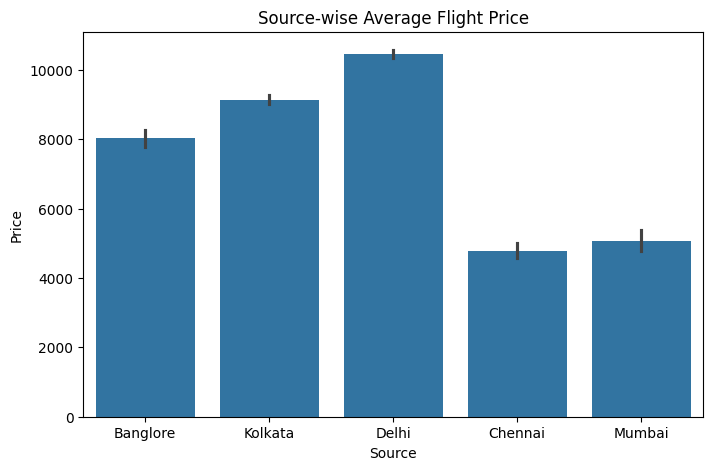

In [19]:
# Create a figure for source-wise price comparison
plt.figure(figsize=(8, 5))

# Compare average prices for different source cities
sns.barplot(data=df, x='Source', y='Price')

# Add graph title
plt.title('Source-wise Average Flight Price')

# Display the graph
plt.show()

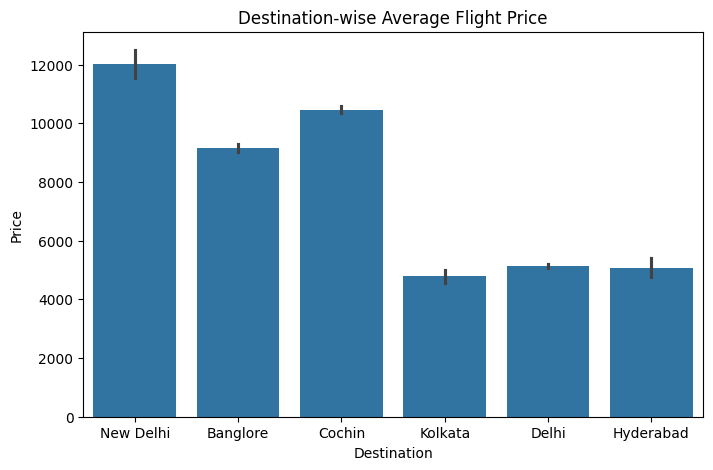

In [20]:
# Create a figure for destination-wise price comparison
plt.figure(figsize=(8, 5))

# Compare average prices for different destination cities
sns.barplot(data=df, x='Destination', y='Price')

# Add graph title
plt.title('Destination-wise Average Flight Price')

# Display the graph
plt.show()

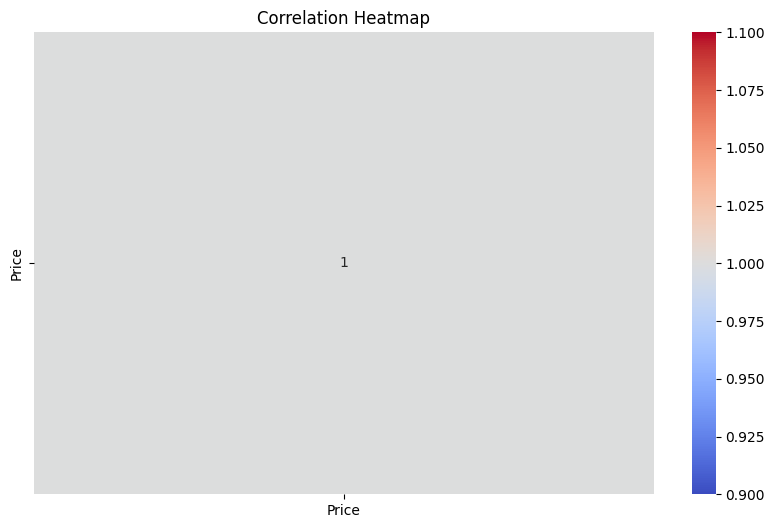

In [21]:
# Calculate correlation between numerical columns
correlation = df.select_dtypes(include=np.number).corr()

# Set the graph size
plt.figure(figsize=(10, 6))

# Create the correlation heatmap
sns.heatmap(correlation, annot=True, cmap='coolwarm')

# Add graph title
plt.title('Correlation Heatmap')

# Display the graph
plt.show()

In [22]:
# Feature Engineering
# Date of Journey
# Extract the day from the Date_of_Journey column
df['Date'] = df['Date_of_Journey'].str.split('/').str[0]

# Extract the month from the Date_of_Journey column
df['Month'] = df['Date_of_Journey'].str.split('/').str[1]

# Extract the year from the Date_of_Journey column
df['Year'] = df['Date_of_Journey'].str.split('/').str[2]

# Convert the Date column into integer format
df['Date'] = df['Date'].astype(int)

# Convert the Month column into integer format
df['Month'] = df['Month'].astype(int)

# Convert the Year column into integer format
df['Year'] = df['Year'].astype(int)

# Display the updated dataset
df.head()


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019


In [23]:
# Remove Date_of_Journey because we extracted its day, month, and year
df.drop('Date_of_Journey', axis=1, inplace=True)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019


In [24]:
# Keep only the time portion and remove any extra text
df['Arrival_Time'] = df['Arrival_Time'].apply(lambda x: x.split(' ')[0])

# Extract the arrival hour
df['Arrival_hour'] = df['Arrival_Time'].str.split(':').str[0]

# Extract the arrival minute
df['Arrival_min'] = df['Arrival_Time'].str.split(':').str[1]

# Convert arrival hour into integer format
df['Arrival_hour'] = df['Arrival_hour'].astype(int)

# Convert arrival minute into integer format
df['Arrival_min'] = df['Arrival_min'].astype(int)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10,2h 50m,non-stop,No info,3897,24,3,2019,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25,19h,2 stops,No info,13882,9,6,2019,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019,21,35


In [25]:
# Remove Arrival_Time because we extracted its hour and minute
df.drop('Arrival_Time', axis=1, inplace=True)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Route,Dep_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,2h 50m,non-stop,No info,3897,24,3,2019,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,7h 25m,2 stops,No info,7662,1,5,2019,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,19h,2 stops,No info,13882,9,6,2019,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,5h 25m,1 stop,No info,6218,12,5,2019,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,4h 45m,1 stop,No info,13302,1,3,2019,21,35


In [26]:
# Extract the departure hour
df['Departure_hour'] = df['Dep_Time'].str.split(':').str[0]

# Extract the departure minute
df['Departure_min'] = df['Dep_Time'].str.split(':').str[1]

# Convert departure hour into integer format
df['Departure_hour'] = df['Departure_hour'].astype(int)

# Convert departure minute into integer format
df['Departure_min'] = df['Departure_min'].astype(int)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Route,Dep_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,2h 50m,non-stop,No info,3897,24,3,2019,1,10,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,7h 25m,2 stops,No info,7662,1,5,2019,13,15,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,19h,2 stops,No info,13882,9,6,2019,4,25,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,5h 25m,1 stop,No info,6218,12,5,2019,23,30,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,4h 45m,1 stop,No info,13302,1,3,2019,21,35,16,50


In [27]:
# Remove Dep_Time because we extracted its hour and minute
df.drop('Dep_Time', axis=1, inplace=True)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,2019,1,10,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,2019,13,15,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,2019,4,25,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,2019,23,30,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,2019,21,35,16,50


In [28]:
# Display all unique values in the Total_Stops column
df['Total_Stops'].unique()

array(['non-stop', '2 stops', '1 stop', '3 stops', nan, '4 stops'],
      dtype=object)

In [29]:
# Display rows where Total_Stops has missing values
df[df['Total_Stops'].isnull()]

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min
9039,Air India,Delhi,Cochin,NaN,23h 40m,NaN,No info,7480,6,5,2019,9,25,9,45


In [30]:
# Find the most frequently occurring value in Total_Stops
df['Total_Stops'].mode()

,Total_Stops
0,1 stop


In [31]:
# Fill missing Total_Stops values with the mode
df['Total_Stops'] = df['Total_Stops'].fillna(df['Total_Stops'].mode()[0])

# Convert stop descriptions into numerical values
df['Total_Stops'] = df['Total_Stops'].map({
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
})

# Display the unique numerical values
df['Total_Stops'].unique()

array([0, 2, 1, 3, 4])

In [32]:
# Remove the Route column from the dataset
df.drop('Route', axis=1, inplace=True)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min
0,IndiGo,Banglore,New Delhi,2h 50m,0,No info,3897,24,3,2019,1,10,22,20
1,Air India,Kolkata,Banglore,7h 25m,2,No info,7662,1,5,2019,13,15,5,50
2,Jet Airways,Delhi,Cochin,19h,2,No info,13882,9,6,2019,4,25,9,25
3,IndiGo,Kolkata,Banglore,5h 25m,1,No info,6218,12,5,2019,23,30,18,5
4,IndiGo,Banglore,New Delhi,4h 45m,1,No info,13302,1,3,2019,21,35,16,50


In [33]:
# Extract the duration hour from the Duration column
df['Duration_Hours'] = df['Duration'].str.extract(r'(\d+)h').astype(float)

# Extract the duration minute from the Duration column
df['Duration_Minutes'] = df['Duration'].str.extract(r'(\d+)m').astype(float)

# Replace missing duration hours with zero
df['Duration_Hours'] = df['Duration_Hours'].fillna(0)

# Replace missing duration minutes with zero
df['Duration_Minutes'] = df['Duration_Minutes'].fillna(0)

# Calculate total flight duration in minutes
df['Total_Duration_Minutes'] = (
    df['Duration_Hours'] * 60 + df['Duration_Minutes']
)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min,Duration_Hours,Duration_Minutes,Total_Duration_Minutes
0,IndiGo,Banglore,New Delhi,2h 50m,0,No info,3897,24,3,2019,1,10,22,20,2.0,50.0,170.0
1,Air India,Kolkata,Banglore,7h 25m,2,No info,7662,1,5,2019,13,15,5,50,7.0,25.0,445.0
2,Jet Airways,Delhi,Cochin,19h,2,No info,13882,9,6,2019,4,25,9,25,19.0,0.0,1140.0
3,IndiGo,Kolkata,Banglore,5h 25m,1,No info,6218,12,5,2019,23,30,18,5,5.0,25.0,325.0
4,IndiGo,Banglore,New Delhi,4h 45m,1,No info,13302,1,3,2019,21,35,16,50,4.0,45.0,285.0


In [34]:
# Remove the original Duration column after extracting numerical values
df.drop('Duration', axis=1, inplace=True)

# Display the updated dataset
df.head()

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min,Duration_Hours,Duration_Minutes,Total_Duration_Minutes
0,IndiGo,Banglore,New Delhi,0,No info,3897,24,3,2019,1,10,22,20,2.0,50.0,170.0
1,Air India,Kolkata,Banglore,2,No info,7662,1,5,2019,13,15,5,50,7.0,25.0,445.0
2,Jet Airways,Delhi,Cochin,2,No info,13882,9,6,2019,4,25,9,25,19.0,0.0,1140.0
3,IndiGo,Kolkata,Banglore,1,No info,6218,12,5,2019,23,30,18,5,5.0,25.0,325.0
4,IndiGo,Banglore,New Delhi,1,No info,13302,1,3,2019,21,35,16,50,4.0,45.0,285.0


In [35]:
# Display unique airline names
df['Airline'].unique()

array(['IndiGo', 'Air India', 'Jet Airways', 'SpiceJet',
       'Multiple carriers', 'GoAir', 'Vistara', 'Air Asia',
       'Vistara Premium economy', 'Jet Airways Business',
       'Multiple carriers Premium economy', 'Trujet'], dtype=object)

In [36]:
# Display unique source cities
df['Source'].unique()

array(['Banglore', 'Kolkata', 'Delhi', 'Chennai', 'Mumbai'], dtype=object)

In [37]:
# Display unique destination cities
df['Destination'].unique()

array(['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad'],
      dtype=object)

In [38]:
# Display unique values in Additional_Info
df['Additional_Info'].unique()

array(['No info', 'In-flight meal not included',
       'No check-in baggage included', '1 Short layover', 'No Info',
       '1 Long layover', 'Change airports', 'Business class',
       'Red-eye flight', '2 Long layover'], dtype=object)

In [39]:
# OneHotEncoder
# Import OneHotEncoder from sklearn
from sklearn.preprocessing import OneHotEncoder

In [40]:
# Create an encoder object
encoder = OneHotEncoder(handle_unknown='ignore')

In [41]:
# Select categorical columns for encoding
categorical_data = df[['Airline', 'Source', 'Destination']]

# Fit the encoder and transform categorical values into a numerical array
encoded_array = encoder.fit_transform(categorical_data).toarray()

# Display the encoded array
encoded_array

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(10463, 23))

In [42]:
# Convert the encoded numerical array into a DataFrame
encoded_df = pd.DataFrame(
    encoded_array,

    # Get the generated encoded column names
    columns=encoder.get_feature_names_out(),

    # Preserve the original DataFrame index
    index=df.index
)

# Display the first five rows of encoded data
encoded_df.head()

,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [43]:
# Remove the original categorical columns after encoding
df.drop(['Airline', 'Source', 'Destination'], axis=1, inplace=True)

# Display the updated dataset
df.head()

,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min,Duration_Hours,Duration_Minutes,Total_Duration_Minutes
0,0,No info,3897,24,3,2019,1,10,22,20,2.0,50.0,170.0
1,2,No info,7662,1,5,2019,13,15,5,50,7.0,25.0,445.0
2,2,No info,13882,9,6,2019,4,25,9,25,19.0,0.0,1140.0
3,1,No info,6218,12,5,2019,23,30,18,5,5.0,25.0,325.0
4,1,No info,13302,1,3,2019,21,35,16,50,4.0,45.0,285.0


In [44]:
# Combine the original DataFrame with the encoded DataFrame
df = pd.concat([df, encoded_df], axis=1)

# Display the final combined dataset
df.head()

,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min,Duration_Hours,Duration_Minutes,Total_Duration_Minutes,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,No info,3897,24,3,2019,1,10,22,20,2.0,50.0,170.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2,No info,7662,1,5,2019,13,15,5,50,7.0,25.0,445.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2,No info,13882,9,6,2019,4,25,9,25,19.0,0.0,1140.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1,No info,6218,12,5,2019,23,30,18,5,5.0,25.0,325.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1,No info,13302,1,3,2019,21,35,16,50,4.0,45.0,285.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [45]:
# Check the final number of rows and columns
df.shape

(10463, 36)

In [46]:
# Display all final column names
df.columns.tolist()

['Total_Stops',
 'Additional_Info',
 'Price',
 'Date',
 'Month',
 'Year',
 'Arrival_hour',
 'Arrival_min',
 'Departure_hour',
 'Departure_min',
 'Duration_Hours',
 'Duration_Minutes',
 'Total_Duration_Minutes',
 'Airline_Air Asia',
 'Airline_Air India',
 'Airline_GoAir',
 'Airline_IndiGo',
 'Airline_Jet Airways',
 'Airline_Jet Airways Business',
 'Airline_Multiple carriers',
 'Airline_Multiple carriers Premium economy',
 'Airline_SpiceJet',
 'Airline_Trujet',
 'Airline_Vistara',
 'Airline_Vistara Premium economy',
 'Source_Banglore',
 'Source_Chennai',
 'Source_Delhi',
 'Source_Kolkata',
 'Source_Mumbai',
 'Destination_Banglore',
 'Destination_Cochin',
 'Destination_Delhi',
 'Destination_Hyderabad',
 'Destination_Kolkata',
 'Destination_New Delhi']

In [47]:
# Check the final data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10463 entries, 0 to 10682
Data columns (total 36 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Total_Stops                                10463 non-null  int64  
 1   Additional_Info                            10463 non-null  object 
 2   Price                                      10463 non-null  int64  
 3   Date                                       10463 non-null  int64  
 4   Month                                      10463 non-null  int64  
 5   Year                                       10463 non-null  int64  
 6   Arrival_hour                               10463 non-null  int64  
 7   Arrival_min                                10463 non-null  int64  
 8   Departure_hour                             10463 non-null  int64  
 9   Departure_min                              10463 non-null  int64  
 10  Duration_Hours             

In [48]:
# Check missing values in the final dataset
df.isnull().sum()

,0
Total_Stops,0
Additional_Info,0
Price,0
Date,0
Month,0
Year,0
Arrival_hour,0
Arrival_min,0
Departure_hour,0
Departure_min,0


In [49]:
# Display the first five rows of the final dataset
df.head()

,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Departure_hour,Departure_min,Duration_Hours,Duration_Minutes,Total_Duration_Minutes,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,No info,3897,24,3,2019,1,10,22,20,2.0,50.0,170.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2,No info,7662,1,5,2019,13,15,5,50,7.0,25.0,445.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2,No info,13882,9,6,2019,4,25,9,25,19.0,0.0,1140.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1,No info,6218,12,5,2019,23,30,18,5,5.0,25.0,325.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1,No info,13302,1,3,2019,21,35,16,50,4.0,45.0,285.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [50]:
# Save the cleaned and feature-engineered dataset as a CSV file
df.to_csv('flight_price_cleaned.csv', index=False)

# Print a confirmation message
print("Dataset saved successfully!")

Dataset saved successfully!
